# 01 — General exploratory data analysis

**Purpose.** Inspect the ICU hourly sepsis table *before* we model it. We identify the schema from the file itself (no assumed column names), describe missingness, class imbalance, demographics, and example vital-sign trajectories.

**Inputs.** `data/raw/dataset.csv`

**Outputs.** EDA figures in `results/figures/`, identified schema in `data/processed/schema.json`, and the preprocessing decisions listed in the summary.


In [1]:
# Set a global random seed and print library versions so this notebook is reproducible.
from pathlib import Path
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs,
    identify_schema, print_schema, save_schema, save_fig,
)

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)
print("PROJECT_ROOT =", PROJECT_ROOT)


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2
PROJECT_ROOT = /Users/shaikniyaz/projects/CSET343_project


## Load the raw table and identify the schema


In [2]:
# Load the CSV and infer which columns are the ID, time, target, vitals, labs, and demographics.
DATA_PATH = PATHS["raw"] / "dataset.csv"
df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)
print("memory_mb:", round(df.memory_usage(deep=True).sum() / 1024**2, 2))
print("\nColumn dtypes:")
print(df.dtypes)
schema = identify_schema(df)
print_schema(schema)
save_schema(schema, PATHS["processed"] / "schema.json")
print("\nSaved schema to", PATHS["processed"] / "schema.json")


shape: (546123, 44)
memory_mb: 183.33

Column dtypes:
Unnamed: 0            int64
Hour                  int64
HR                  float64
O2Sat               float64
Temp                float64
SBP                 float64
MAP                 float64
DBP                 float64
Resp                float64
EtCO2               float64
BaseExcess          float64
HCO3                float64
FiO2                float64
pH                  float64
PaCO2               float64
SaO2                float64
AST                 float64
BUN                 float64
Alkalinephos        float64
Calcium             float64
Chloride            float64
Creatinine          float64
Bilirubin_direct    float64
Glucose             float64
Lactate             float64
Magnesium           float64
Phosphate           float64
Potassium           float64
Bilirubin_total     float64
TroponinI           float64
Hct                 float64
Hgb                 float64
PTT                 float64
WBC                 fl

**What we learned.** The file is PhysioNet 2019-style hourly ICU data. `Patient_ID` is the stay identifier, `Hour` is the time index, `SepsisLabel` is the target, and one trailing row in this Kaggle dump is empty. `Unnamed: 0` duplicates `Hour`. `EtCO2` is entirely missing in this extract.


## Shape, patients, and sequence-length distribution


rows after dropping empty record: 546122
unique patients: 14057
count    14057.000000
mean        38.850537
std         22.234872
min          8.000000
25%         25.000000
50%         39.000000
75%         47.000000
max        336.000000
dtype: float64


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  {


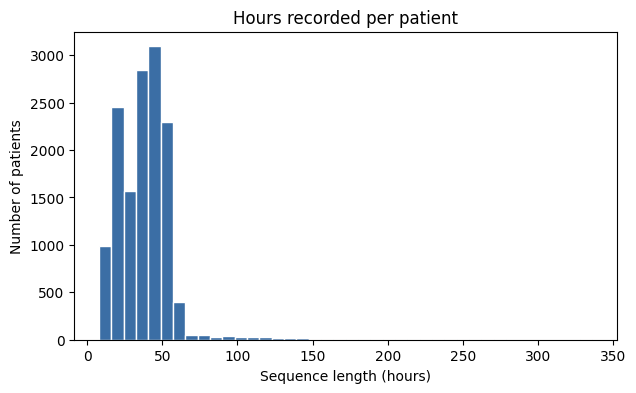

In [3]:
# Count unique patients and how many hourly rows each stay has. This tells us typical ICU length.
pid, hour, target = schema["patient_id"], schema["hour"], schema["target"]
# Drop the truncated last record so patient counts are honest.
df = df.dropna(subset=[pid, target]).copy()
df[pid] = df[pid].astype(int)
print("rows after dropping empty record:", len(df))
print("unique patients:", df[pid].nunique())
seq_len = df.groupby(pid).size()
print(seq_len.describe())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(seq_len, bins=40, color="#3b6ea5", edgecolor="white")
ax.set_title("Hours recorded per patient")
ax.set_xlabel("Sequence length (hours)")
ax.set_ylabel("Number of patients")
save_fig(fig, PATHS["figures"] / "01_sequence_length_hist.png")
plt.show()


**What we learned.** Stays are short on average (tens of hours, not days). A 24-hour sliding window will need left-padding for many patients.


## Target analysis: row-level and patient-level prevalence


row-level sepsis prevalence:   2.170%
patient-level sepsis prevalence: 8.814%  (1239/14057)
positive hours: 11850 negative hours: 534272


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  },


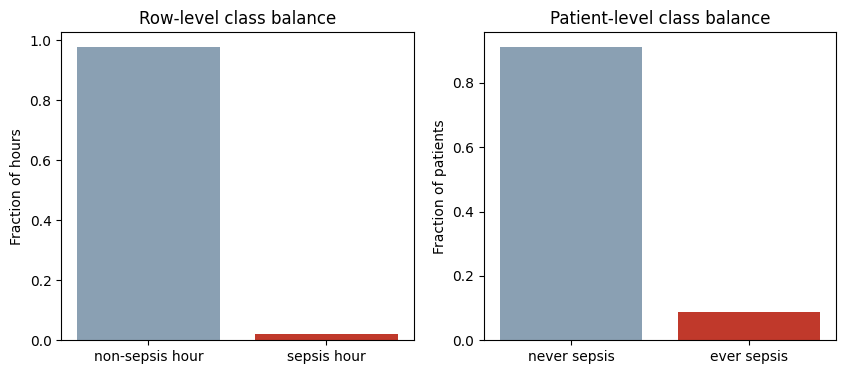

In [4]:
# Sepsis hours are rare; we also ask whether the *patient* ever becomes septic. Models must not treat this as a balanced problem.
row_rate = df[target].mean()
ever = df.groupby(pid)[target].max()
print("row-level sepsis prevalence:   {:.3%}".format(row_rate))
print("patient-level sepsis prevalence: {:.3%}  ({}/{})".format(ever.mean(), int(ever.sum()), len(ever)))
print("positive hours:", int(df[target].sum()), "negative hours:", int((df[target]==0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].bar(["non-sepsis hour", "sepsis hour"], [(df[target]==0).mean(), (df[target]==1).mean()], color=["#8aa0b3", "#c0392b"])
axes[0].set_title("Row-level class balance")
axes[0].set_ylabel("Fraction of hours")
axes[1].bar(["never sepsis", "ever sepsis"], [1-ever.mean(), ever.mean()], color=["#8aa0b3", "#c0392b"])
axes[1].set_title("Patient-level class balance")
axes[1].set_ylabel("Fraction of patients")
save_fig(fig, PATHS["figures"] / "01_class_imbalance.png")
plt.show()


**What we learned.** About 2% of hours and about 9% of patients are positive. Accuracy would look excellent if we always predicted 0. We will report **PR-AUC** next to ROC-AUC and use `scale_pos_weight` / `pos_weight` on the training set only.


## Missing values


EtCO2               100.000000
TroponinI            99.874021
Bilirubin_direct     99.850217
Fibrinogen           99.237533
Bilirubin_total      98.769872
Alkalinephos         98.544281
AST                  98.502349
Lactate              96.578970
PTT                  95.158774
SaO2                 95.114645
Calcium              95.021991
Phosphate            94.945086
Platelets            93.482958
Creatinine           93.369247
WBC                  92.505521
Magnesium            92.237815
HCO3                 91.966081
BUN                  91.860793
Chloride             91.703685
PaCO2                91.290957


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:21: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "metadata": {},


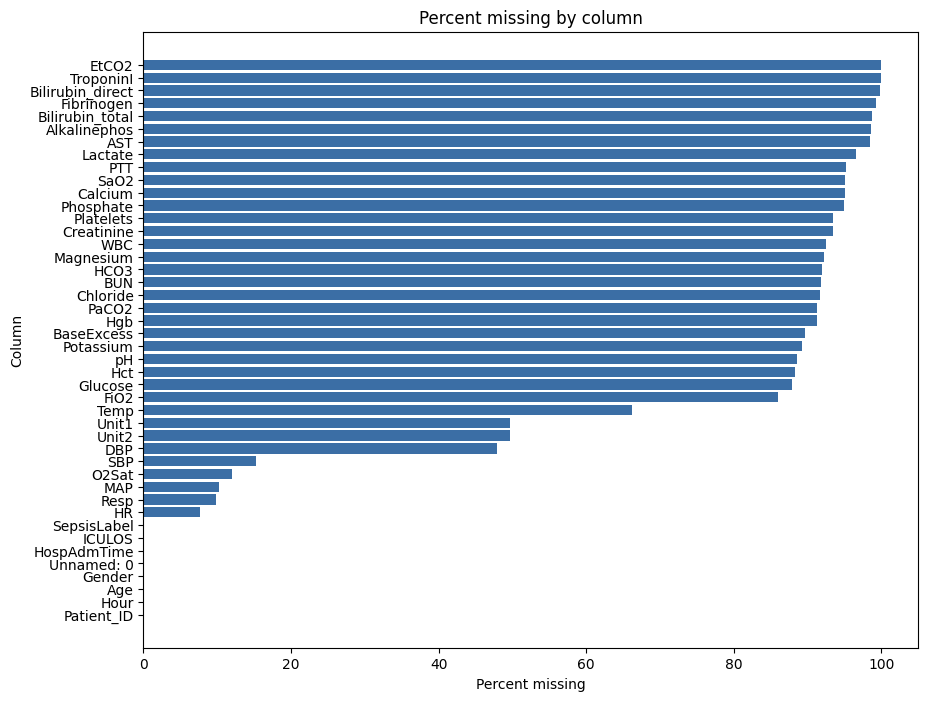

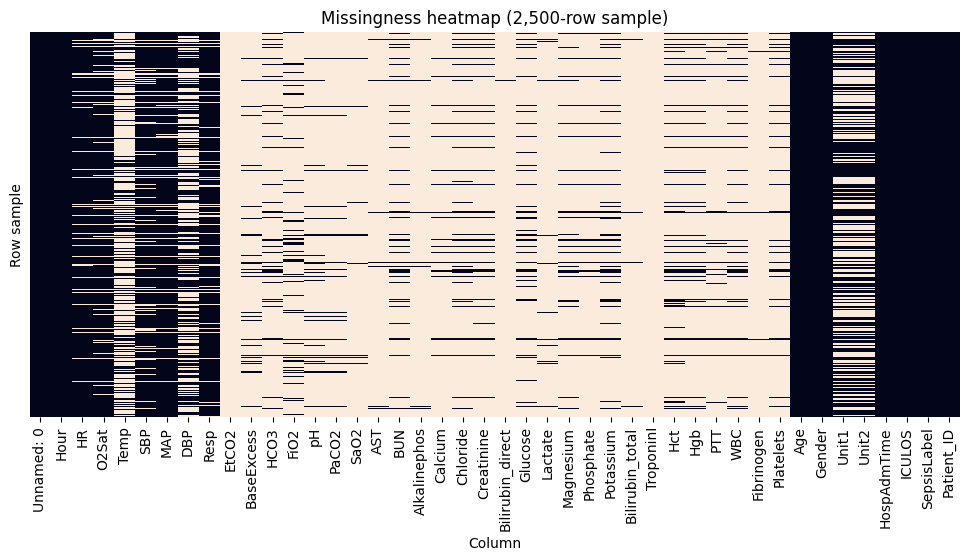

In [5]:
# Clinical labs are drawn rarely, so missingness is expected — not a data bug. We plot % missing and a small heatmap.
miss = df.isna().mean().sort_values(ascending=False) * 100
print(miss.head(20).to_string())

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(miss.index[::-1], miss.values[::-1], color="#3b6ea5")
ax.set_title("Percent missing by column")
ax.set_xlabel("Percent missing")
ax.set_ylabel("Column")
save_fig(fig, PATHS["figures"] / "01_missing_bar.png")
plt.show()

# Heatmap on a random sample of rows (full table is too large to visualize).
sample = df.sample(n=min(2500, len(df)), random_state=SEED)
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(sample.isna(), cbar=False, yticklabels=False, ax=ax)
ax.set_title("Missingness heatmap (2,500-row sample)")
ax.set_xlabel("Column")
ax.set_ylabel("Row sample")
save_fig(fig, PATHS["figures"] / "01_missing_heatmap.png")
plt.show()


**What we learned.** Vitals are mostly present; labs are 85–99% missing because they are measured infrequently. Missingness itself can be a signal (a lactate was ordered). We will add measurement-indicator columns and forward-fill *within* each patient only.


## Vital / lab distributions by sepsis vs non-sepsis


Rough outlier fences (1.5 IQR) for vitals:
  HR        IQR fence [38.5, 130.5]  outlier_frac=0.009
  O2Sat     IQR fence [90.8, 104.8]  outlier_frac=0.017
  Temp      IQR fence [35.1, 39.1]  outlier_frac=0.015
  SBP       IQR fence [60.0, 180.0]  outlier_frac=0.009
  MAP       IQR fence [39.3, 116.7]  outlier_frac=0.016
  DBP       IQR fence [28.2, 90.2]  outlier_frac=0.020
  Resp      IQR fence [4.5, 32.5]  outlier_frac=0.017


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  "\n",
/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropp

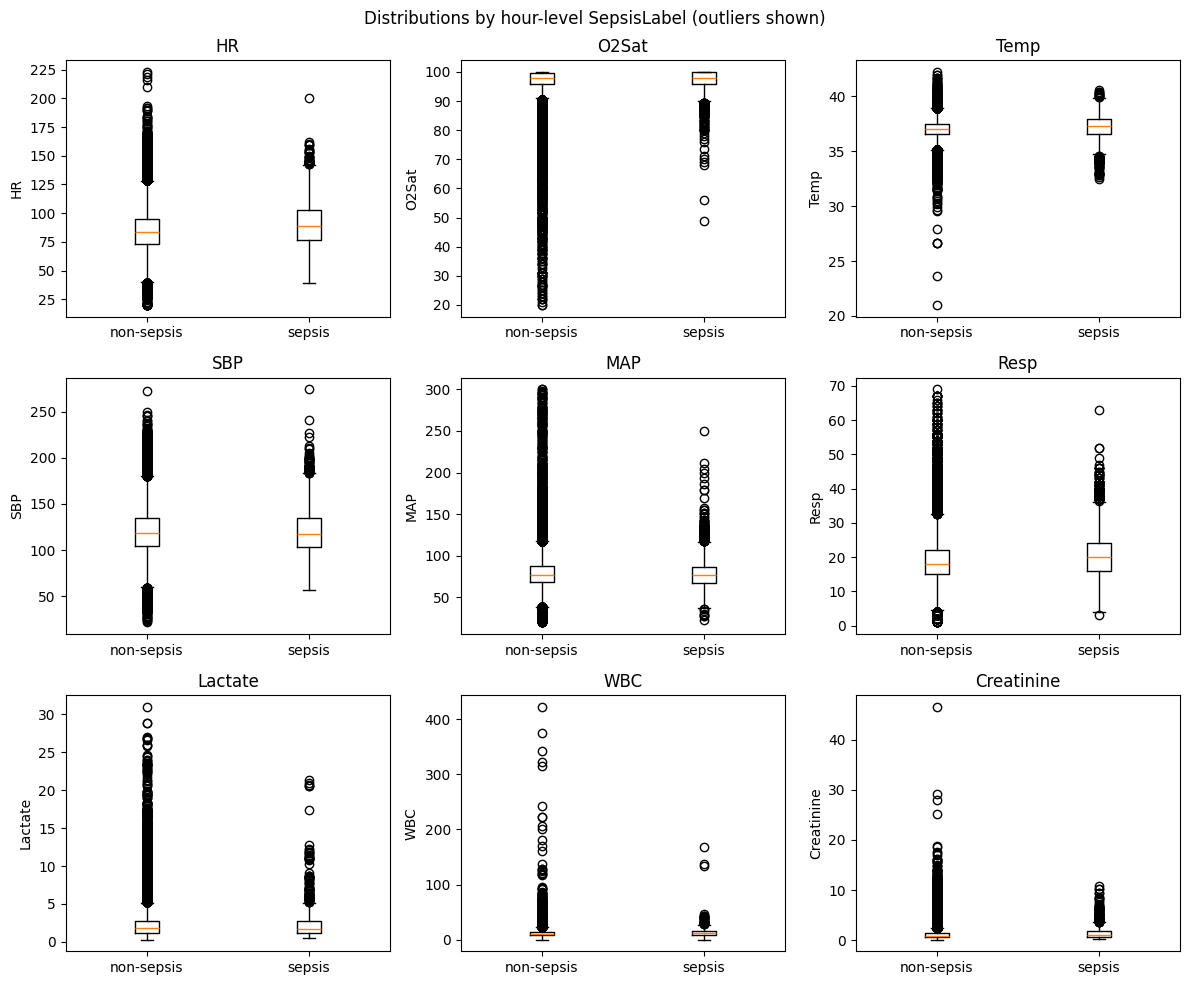

In [6]:
# Compare a few clinical variables when the hour is labeled septic vs not. Outliers are expected in ICU data.
plot_cols = [c for c in ["HR", "O2Sat", "Temp", "SBP", "MAP", "Resp", "Lactate", "WBC", "Creatinine"] if c in df.columns]
n = len(plot_cols)
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
axes = axes.ravel()
for i, col in enumerate(plot_cols):
    a = df.loc[df[target]==0, col].dropna()
    b = df.loc[df[target]==1, col].dropna()
    axes[i].boxplot([a, b], labels=["non-sepsis", "sepsis"], showfliers=True)
    axes[i].set_title(col)
    axes[i].set_ylabel(col)
for j in range(i+1, len(axes)):
    axes[j].axis("off")
fig.suptitle("Distributions by hour-level SepsisLabel (outliers shown)")
fig.tight_layout()
save_fig(fig, PATHS["figures"] / "01_vitals_by_label.png")
plt.show()

print("Rough outlier fences (1.5 IQR) for vitals:")
for col in schema["vitals"]:
    s = df[col].dropna()
    if s.empty:
        continue
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    frac = ((s < lo) | (s > hi)).mean()
    print(f"  {col:8s}  IQR fence [{lo:.1f}, {hi:.1f}]  outlier_frac={frac:.3f}")


**What we learned.** Heart rate, respiration, and lactate tend to sit higher on sepsis hours, but overlap is large. Extreme values exist; we will not clip aggressively because extremes can be clinically real. Scaling (not min-max clipping) is the safer default.


## Correlation heatmap of numeric features


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "\n",


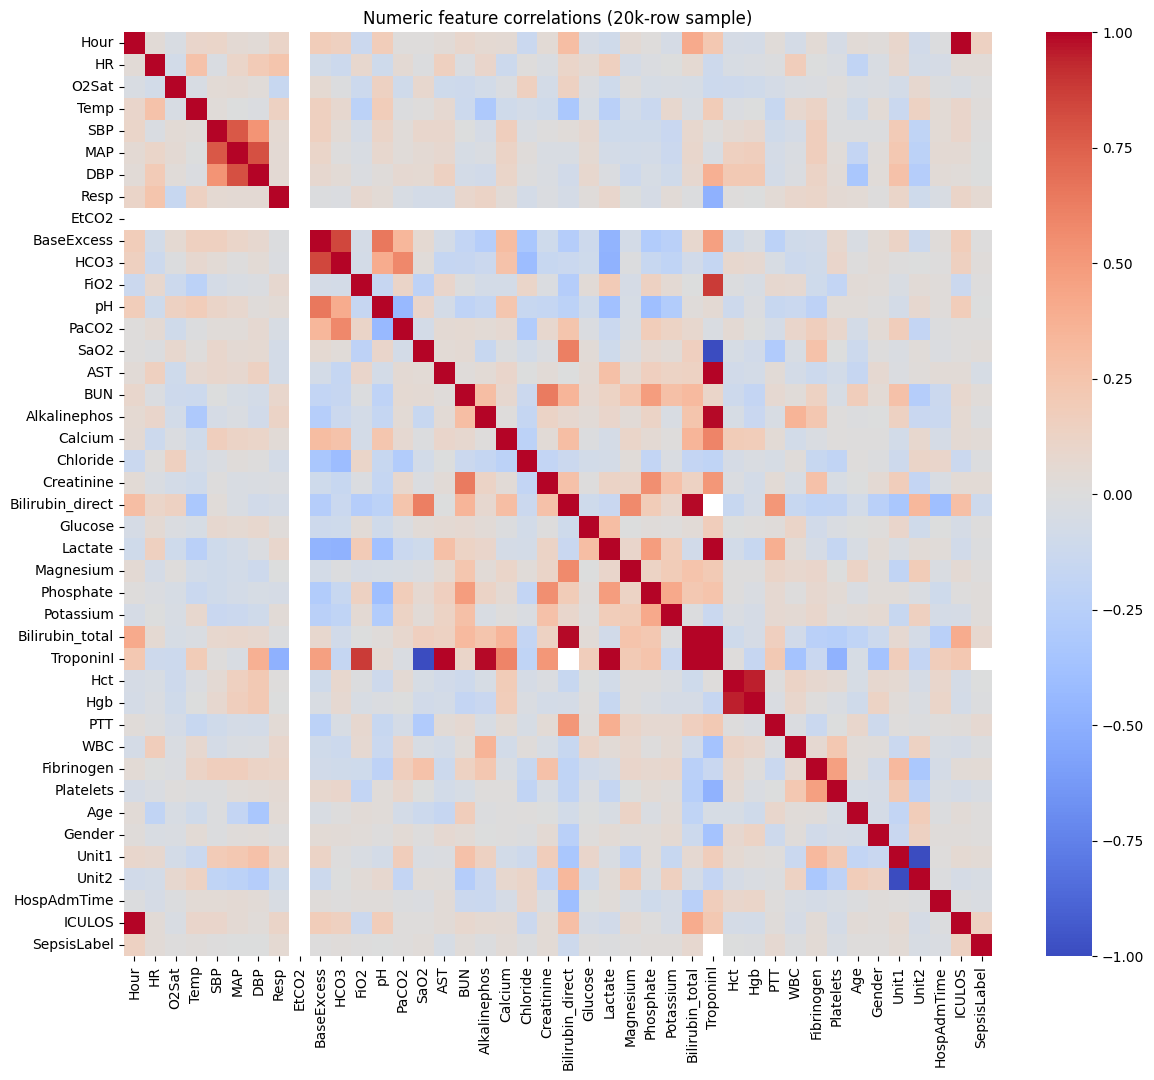

In [7]:
# Pairwise correlations on a sample. Highly collinear vitals (SBP/MAP/DBP) are expected.
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
# Skip ID-like columns so the heatmap is readable.
skip = {pid, "Unnamed: 0"}
use = [c for c in num_cols if c not in skip]
corr = df[use].sample(n=min(20000, len(df)), random_state=SEED).corr()
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, xticklabels=True, yticklabels=True)
ax.set_title("Numeric feature correlations (20k-row sample)")
save_fig(fig, PATHS["figures"] / "01_correlation_heatmap.png")
plt.show()


**What we learned.** Blood-pressure columns are strongly correlated; Hour and ICULOS are related but not identical. Tree models can keep collinear features; deep models will still benefit from standardization.


## Demographics: age, gender, and sepsis rate


Gender
1.0    8160
0.0    5897
Name: count, dtype: int64
Assumption: Gender 0 = female, 1 = male (PhysioNet 2019 coding).
             mean  count
age_bin                 
<40      0.082211   1411
40-65    0.086219   5718
65+      0.090935   6928


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  {


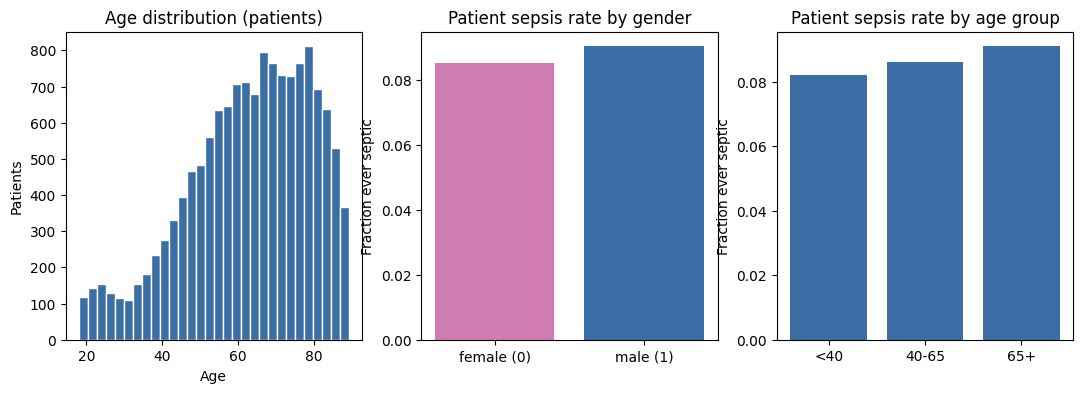

In [8]:
# Age and gender are constant within a stay. We look at sepsis rate by group (fairness comes later in notebook 08).
demo = df.groupby(pid).agg(Age=("Age", "first"), Gender=("Gender", "first"), ever_sepsis=(target, "max")).dropna()
print(demo["Gender"].value_counts(dropna=False))
print("Assumption: Gender 0 = female, 1 = male (PhysioNet 2019 coding).")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].hist(demo["Age"], bins=30, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Age distribution (patients)")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Patients")

g = demo.groupby("Gender")["ever_sepsis"].mean()
axes[1].bar(["female (0)", "male (1)"], [g.get(0, np.nan), g.get(1, np.nan)], color=["#d17bb3", "#3b6ea5"])
axes[1].set_title("Patient sepsis rate by gender")
axes[1].set_ylabel("Fraction ever septic")

demo["age_bin"] = pd.cut(demo["Age"], bins=[0, 40, 65, 120], labels=["<40", "40-65", "65+"])
r = demo.groupby("age_bin", observed=True)["ever_sepsis"].mean()
axes[2].bar(r.index.astype(str), r.values, color="#3b6ea5")
axes[2].set_title("Patient sepsis rate by age group")
axes[2].set_ylabel("Fraction ever septic")
save_fig(fig, PATHS["figures"] / "01_demographics.png")
plt.show()
print(demo.groupby("age_bin", observed=True)["ever_sepsis"].agg(["mean", "count"]))


**What we learned.** The cohort is older adults. Sepsis rate is not identical across gender and age; notebook 08 will quantify fairness gaps rather than assume the model is even.


## Example trajectories (3 sepsis, 3 non-sepsis)


/Users/shaikniyaz/projects/CSET343_project/notebooks/01_eda_overview.ipynb:34: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "",


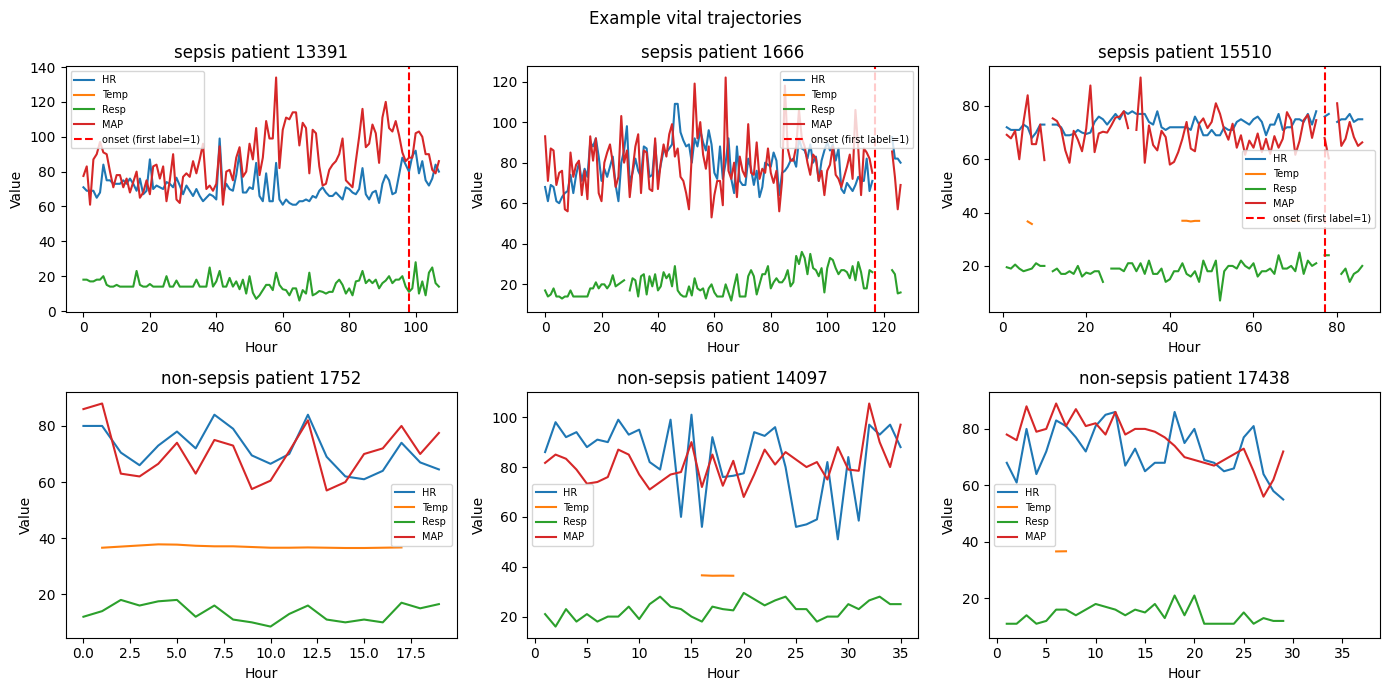

In [9]:
# Plot a few vitals over time. For septic stays we mark the first hour where SepsisLabel becomes 1 ("onset" in this dataset).
rng = np.random.default_rng(SEED)
septic_ids = ever[ever == 1].index.to_numpy()
non_ids = ever[ever == 0].index.to_numpy()

def pick_with_length(ids, n=3, min_len=20):
    long_enough = [i for i in ids if seq_len.loc[i] >= min_len]
    return rng.choice(long_enough, size=n, replace=False)

s_ids = pick_with_length(septic_ids, 3)
n_ids = pick_with_length(non_ids, 3)
vitals_plot = [c for c in ["HR", "Temp", "Resp", "MAP"] if c in df.columns]

def plot_stay(ax, stay, title, mark_onset):
    stay = stay.sort_values(hour)
    for v in vitals_plot:
        ax.plot(stay[hour], stay[v], label=v)
    if mark_onset and (stay[target] == 1).any():
        onset = stay.loc[stay[target] == 1, hour].iloc[0]
        ax.axvline(onset, color="red", linestyle="--", label="onset (first label=1)")
    ax.set_title(title)
    ax.set_xlabel("Hour")
    ax.set_ylabel("Value")
    ax.legend(fontsize=7)

fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=False)
for ax, i in zip(axes[0], s_ids):
    plot_stay(ax, df[df[pid] == i], f"sepsis patient {i}", True)
for ax, i in zip(axes[1], n_ids):
    plot_stay(ax, df[df[pid] == i], f"non-sepsis patient {i}", False)
fig.suptitle("Example vital trajectories")
fig.tight_layout()
save_fig(fig, PATHS["figures"] / "01_example_trajectories.png")
plt.show()


**What we learned.** Onset in *this dataset* is the first hour with `SepsisLabel=1`. PhysioNet already shifts labels earlier than bedside clinical onset (typically up to 6 hours), so "early detection time" here is relative to the **label**, not an independent gold-standard timestamp.


## Summary and preprocessing decisions

1. **Drop** `Unnamed: 0` (duplicate of `Hour`), **drop** `EtCO2` (100% missing), **drop** the empty trailing row.
2. **Split by patient**, stratified on ever-sepsis, 70/15/15. Fit imputers and scalers on train only.
3. **Missing data:** forward-fill inside a stay; remaining gaps get the train median; add binary "was this lab measured?" columns.
4. **Imbalance:** do not resample the test set. Use `scale_pos_weight` (XGBoost) and `pos_weight` (deep models). Headline metrics are PR-AUC and recall, not accuracy.
5. **Two representations:** tabular rows with rolling/delta features for XGBoost; 24-hour sliding windows for LSTM/TCN/Transformer.
6. **Onset definition:** first hour with `SepsisLabel=1` for that patient.


### Notebook 01 complete


In [10]:
# Quick confirmation that the schema file is on disk for later notebooks.
print("schema exists:", (PATHS["processed"] / "schema.json").exists())
print("figures written to", PATHS["figures"])
print("Done with notebook 01.")


schema exists: True
figures written to /Users/shaikniyaz/projects/CSET343_project/results/figures
Done with notebook 01.
